<a href="https://colab.research.google.com/github/anazzmuhmad/unsupervised-learning-case-study/blob/main/unsupervised_learning_case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
df = pd.read_csv('/content/drive/MyDrive/DSA/Datasets/adult_dataset.csv')
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

import warnings
warnings.filterwarnings('ignore')

Load the dataset and understand the data

In [7]:
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
print(df.dtypes)

Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


\nColumn names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
\nData types:
age               float64
workclass          object
fnlwgt              int64
education          object
education-num       int64
marital-status     object
occupation         object
relationship       object
race               object
sex                object
capital-gain        int64
capital-loss        int64
hours-per-week    float64
native-country     object
income             object
dtype: object


In [8]:
# Check missing values and '?' placeholders
df = df.replace(r'^\\s*\\?\\s*$', np.nan, regex=True)

print("Missing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


,0
workclass,3362
occupation,3357
native-country,2705
hours-per-week,2442
age,2442
fnlwgt,0
education,0
marital-status,0
education-num,0
relationship,0


Duplicate rows: 16


Data preprocessing

In [10]:
# Keep income separately. It must NOT be used to train clustering models.
if 'income' in df.columns:
    income_actual = df['income'].astype('string').str.strip().str.rstrip('.')
else:
    income_actual = None

X = df.drop(columns=['income'], errors='ignore').copy()

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [11]:
# Fill missing numerical values with median
for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

# Fill missing categorical values with mode
for col in cat_cols:
    mode_value = X[col].mode(dropna=True)
    fill_value = mode_value.iloc[0] if len(mode_value) else "Unknown"
    X[col] = X[col].fillna(fill_value)

print("Remaining missing values:", X.isnull().sum().sum())

Remaining missing values: 0


In [12]:
# Detect and treat outliers using the IQR method.
# For age and hours-per-week, cap extreme values at IQR limits.
# Other numeric columns are retained because high capital gains/losses can be meaningful.
outlier_cols = [c for c in ['age', 'hours-per-week'] if c in X.columns]

for col in outlier_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    X[col] = X[col].clip(lower_limit, upper_limit)

print("Outlier treatment completed for:", outlier_cols)

Outlier treatment completed for: ['age', 'hours-per-week']


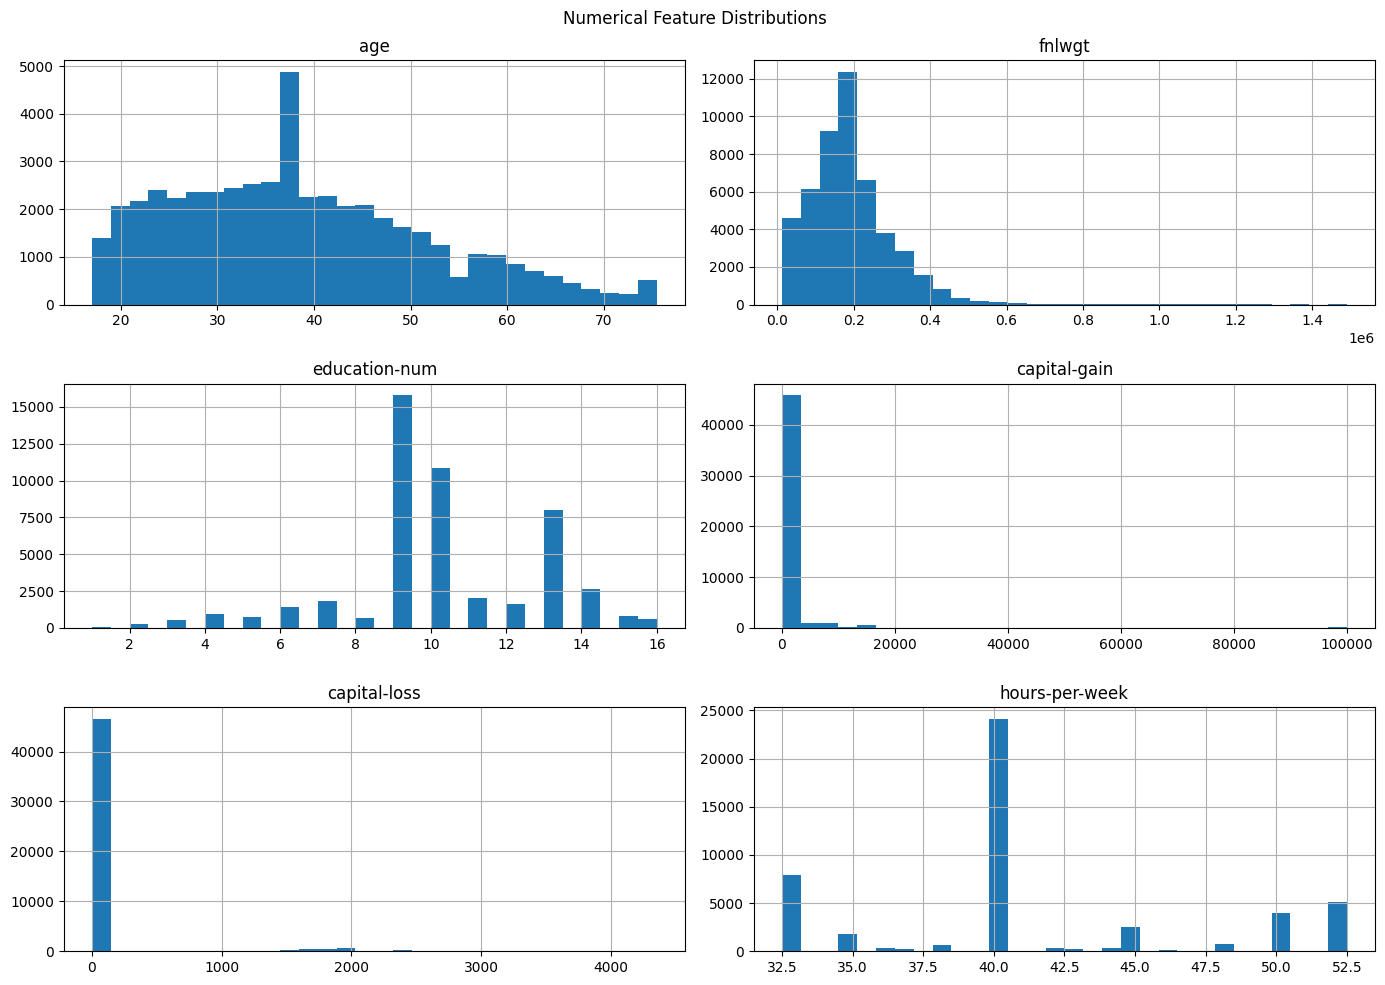

In [13]:
# Visualize numerical feature distributions
X[num_cols].hist(figsize=(14, 10), bins=30)
plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

In [14]:
# One-hot encode categorical columns and standardize numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

X_processed = preprocessor.fit_transform(X)

# Convert sparse output to dense if needed for PCA and clustering
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("Processed data shape:", X_processed.shape)

Processed data shape: (48842, 108)


Explained variance by first two components: 0.26069176172721875


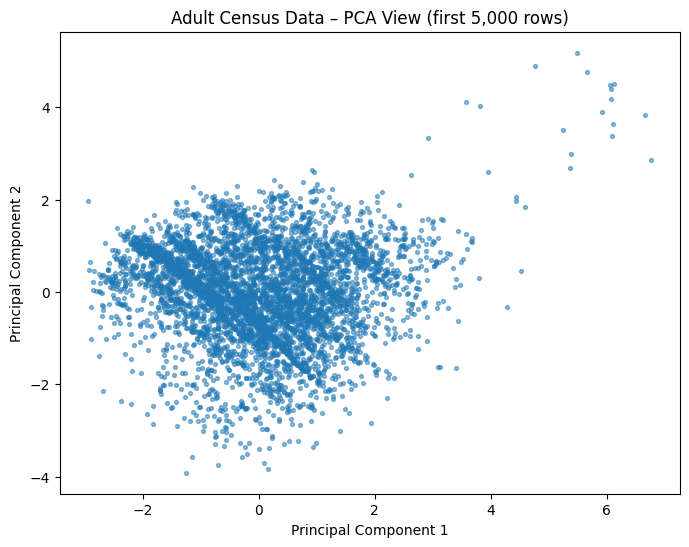

In [15]:
# PCA reduces the processed features to 2 dimensions for plotting.
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_processed)

print("Explained variance by first two components:",
      pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:5000, 0], X_pca[:5000, 1], s=8, alpha=0.5)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Adult Census Data – PCA View (first 5,000 rows)")
plt.show()


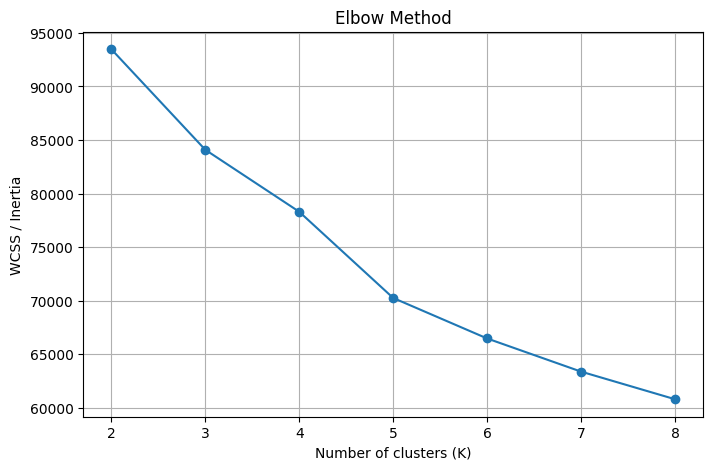

In [16]:
# Use a reproducible sample to make model selection faster in Colab
rng = np.random.RandomState(42)
sample_size = min(10000, X_processed.shape[0])
sample_idx = rng.choice(X_processed.shape[0], size=sample_size, replace=False)
X_sample = X_processed[sample_idx]

# Elbow method: calculate WCSS for K = 2 to 8
wcss = []
k_values = range(2, 9)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sample)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker='o')
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [17]:
# Silhouette score for K = 2 to 8 (calculated on a smaller sample)
silhouette_results = {}

sil_idx = rng.choice(len(X_sample), size=min(3000, len(X_sample)), replace=False)
X_sil = X_sample[sil_idx]

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_sil)
    score = silhouette_score(X_sil, labels)
    silhouette_results[k] = score

print("Silhouette scores:")
for k, score in silhouette_results.items():
    print(f"K={k}: {score:.4f}")

best_k = max(silhouette_results, key=silhouette_results.get)
print("\\nK with the highest silhouette score:", best_k)

# You can change this after inspecting the elbow graph.
chosen_k = best_k

Silhouette scores:
K=2: 0.1027
K=3: 0.1220
K=4: 0.1203
K=5: 0.1140
K=6: 0.1208
K=7: 0.1168
K=8: 0.1188
\nK with the highest silhouette score: 3


In [18]:
# Fit final K-Means model on the complete dataset
kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_processed)

clustered_df = df.copy()
clustered_df['KMeans_Cluster'] = kmeans_labels

print(clustered_df['KMeans_Cluster'].value_counts().sort_index())

KMeans_Cluster
0    24410
1    22195
2     2237
Name: count, dtype: int64


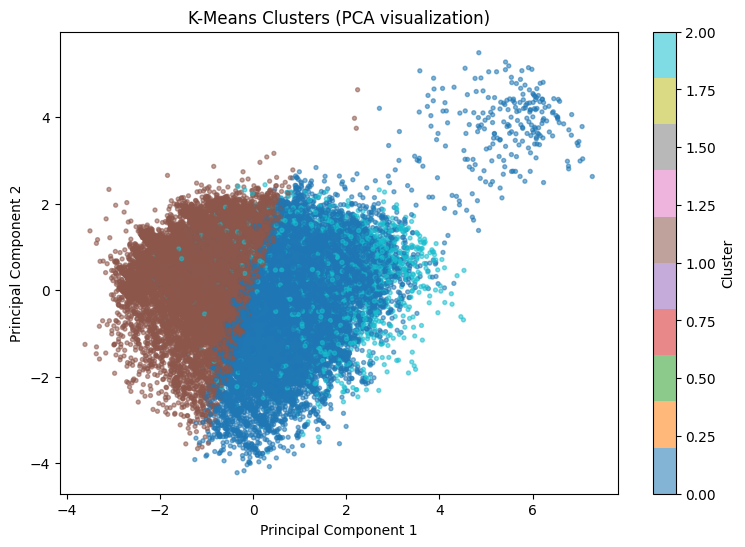

In [19]:
# Visualize K-Means clusters using the PCA coordinates
plt.figure(figsize=(9, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10',
            s=8, alpha=0.55)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (PCA visualization)")
plt.colorbar(label="Cluster")
plt.show()

In [20]:
# Agglomerative clustering is computationally expensive on large datasets.
# Run it on a random sample of up to 5,000 rows.
agg_size = min(5000, X_processed.shape[0])
agg_idx = rng.choice(X_processed.shape[0], size=agg_size, replace=False)
X_agg = X_processed[agg_idx]

agg = AgglomerativeClustering(n_clusters=chosen_k, linkage='ward')
agg_labels = agg.fit_predict(X_agg)

print("Agglomerative cluster counts:")
print(pd.Series(agg_labels).value_counts().sort_index())
print("Agglomerative silhouette score:",
      round(silhouette_score(X_agg, agg_labels), 4))

Agglomerative cluster counts:
0    2474
1     237
2    2289
Name: count, dtype: int64
Agglomerative silhouette score: 0.1108


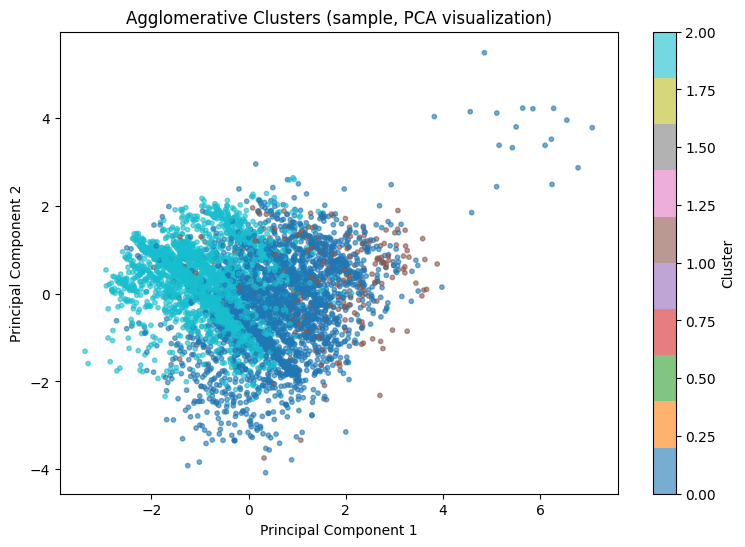

In [21]:
# PCA visualization of the Agglomerative sample
X_agg_pca = pca.transform(X_agg)

plt.figure(figsize=(9, 6))
plt.scatter(X_agg_pca[:, 0], X_agg_pca[:, 1], c=agg_labels,
            cmap='tab10', s=10, alpha=0.6)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clusters (sample, PCA visualization)")
plt.colorbar(label="Cluster")
plt.show()

In [22]:
# Summarize numeric characteristics for each K-Means cluster
numeric_profile = clustered_df.groupby('KMeans_Cluster')[num_cols].mean().round(2)
display(numeric_profile)

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
KMeans_Cluster,,,,,,
0,46.13,178016.82,10.51,1982.65,0.41,44.72
1,30.09,202609.17,9.52,194.07,0.73,35.45
2,41.93,188321.17,11.00,0.00,1898.80,43.32


In [23]:
# Most common category in each cluster
for col in cat_cols:
    print("\\nMost common", col, "by cluster:")
    display(
        clustered_df.groupby('KMeans_Cluster')[col]
        .agg(lambda x: x.value_counts().index[0])
        .to_frame(name='Most_Common_Value')
    )

\nMost common workclass by cluster:


,Most_Common_Value
KMeans_Cluster,
0,Private
1,Private
2,Private


\nMost common education by cluster:


,Most_Common_Value
KMeans_Cluster,
0,HS-grad
1,HS-grad
2,HS-grad


\nMost common marital-status by cluster:


,Most_Common_Value
KMeans_Cluster,
0,Married-civ-spouse
1,Never-married
2,Married-civ-spouse


... (6 outputs left out)

\nMost common sex by cluster:


,Most_Common_Value
KMeans_Cluster,
0,Male
1,Female
2,Male


\nMost common native-country by cluster:


,Most_Common_Value
KMeans_Cluster,
0,United-States
1,United-States
2,United-States


In [24]:
# This comparison is for interpretation only.
if income_actual is not None:
    comparison = pd.crosstab(
        clustered_df['KMeans_Cluster'],
        income_actual,
        normalize='index'
    ).round(3) * 100
    print("Income percentage within each cluster:")
    display(comparison)
else:
    print("No income column was found.")

Income percentage within each cluster:


income,<=50K,>50K
KMeans_Cluster,,
0,60.9,39.1
1,95.5,4.5
2,48.9,51.1


In [25]:
# Cluster sizes
cluster_sizes = clustered_df['KMeans_Cluster'].value_counts().sort_index()
print("Cluster sizes:")
display(cluster_sizes.to_frame("Number_of_people"))

print("Total people clustered:", len(clustered_df))
print("Number of clusters:", clustered_df['KMeans_Cluster'].nunique())

Cluster sizes:


,Number_of_people
KMeans_Cluster,
0,24410
1,22195
2,2237


Total people clustered: 48842
Number of clusters: 3
